# VQGAN autoencoder demo

Encodes chest X-rays into discrete latent codes with the pre-trained VQGANs in `xrv.baseline_models.ieee8023` and decodes them back, comparing both model sizes on four example images.

The weights are downloaded on first use (306 MB for `cxr2-vqgan-768-sd`, 1.23 GB for `cxr2-vqgan-768-msdd`).

In [1]:
import sys
sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchxrayvision as xrv

## Load example images

Images are in the TorchXRayVision range of [-1024, 1024]. The model's native resolution is 768x768, so we crop and resize to that.

torch.Size([4, 1, 768, 768]) -1024.0 1018.645751953125


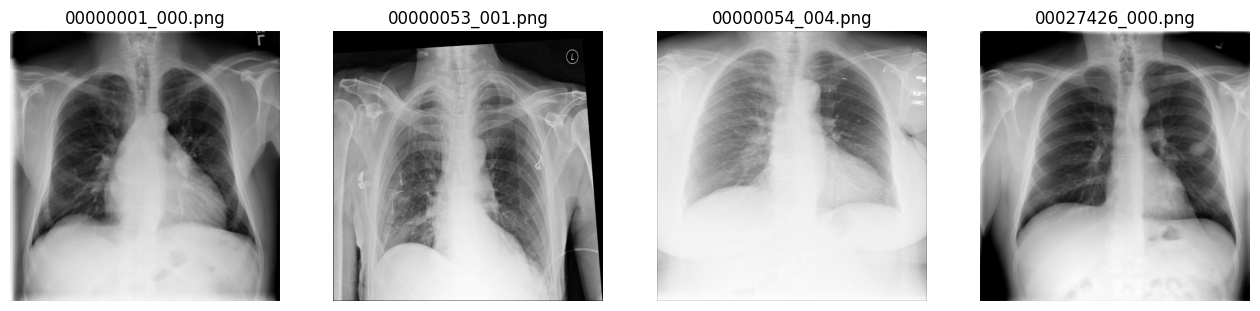

In [2]:
import torchvision

files = ["00000001_000.png", "00000053_001.png", "00000054_004.png", "00027426_000.png"]
transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(768)])
imgs = torch.stack([torch.from_numpy(transform(xrv.utils.load_image("../tests/" + f))) for f in files])  # (4, 1, 768, 768)

print(imgs.shape, imgs.min().item(), imgs.max().item())
fig, axs = plt.subplots(1, len(files), figsize=(16, 4))
for ax, im, f in zip(axs, imgs, files):
    ax.imshow(im[0], cmap="gray"); ax.set_title(f); ax.axis("off")

## Load both models

In [3]:
vqs = {w: xrv.baseline_models.ieee8023.VQGAN(weights=w) for w in xrv.baseline_models.ieee8023.model_urls}
for w, vq in vqs.items():
    print(w, "-", vq.description)

cxr2-vqgan-768-sd - Trained on  mimic_ch pc vin siim objectcxr chex at 768x768 resolution (306 MB).
cxr2-vqgan-768-msdd - Trained on mimic_ch pc vin siim objectcxr chex at 768x768 resolution (1.23 GB).


## Encode, decode and compute the differences

In [4]:
zs, recons, diffs = {}, {}, {}
with torch.no_grad():
    for w, vq in vqs.items():
        zs[w] = vq.encode(imgs)
        recons[w] = vq.decode(zs[w])
        diffs[w] = imgs - recons[w]
        print(f"{w}: latent {tuple(zs[w].shape[1:])}, mean absolute error per image",
              [round(d.abs().mean().item(), 1) for d in diffs[w]])

cxr2-vqgan-768-sd: latent (64, 24, 24), mean absolute error per image [36.8, 49.0, 32.7, 32.4]
cxr2-vqgan-768-msdd: latent (128, 12, 12), mean absolute error per image [66.3, 82.4, 44.8, 61.0]


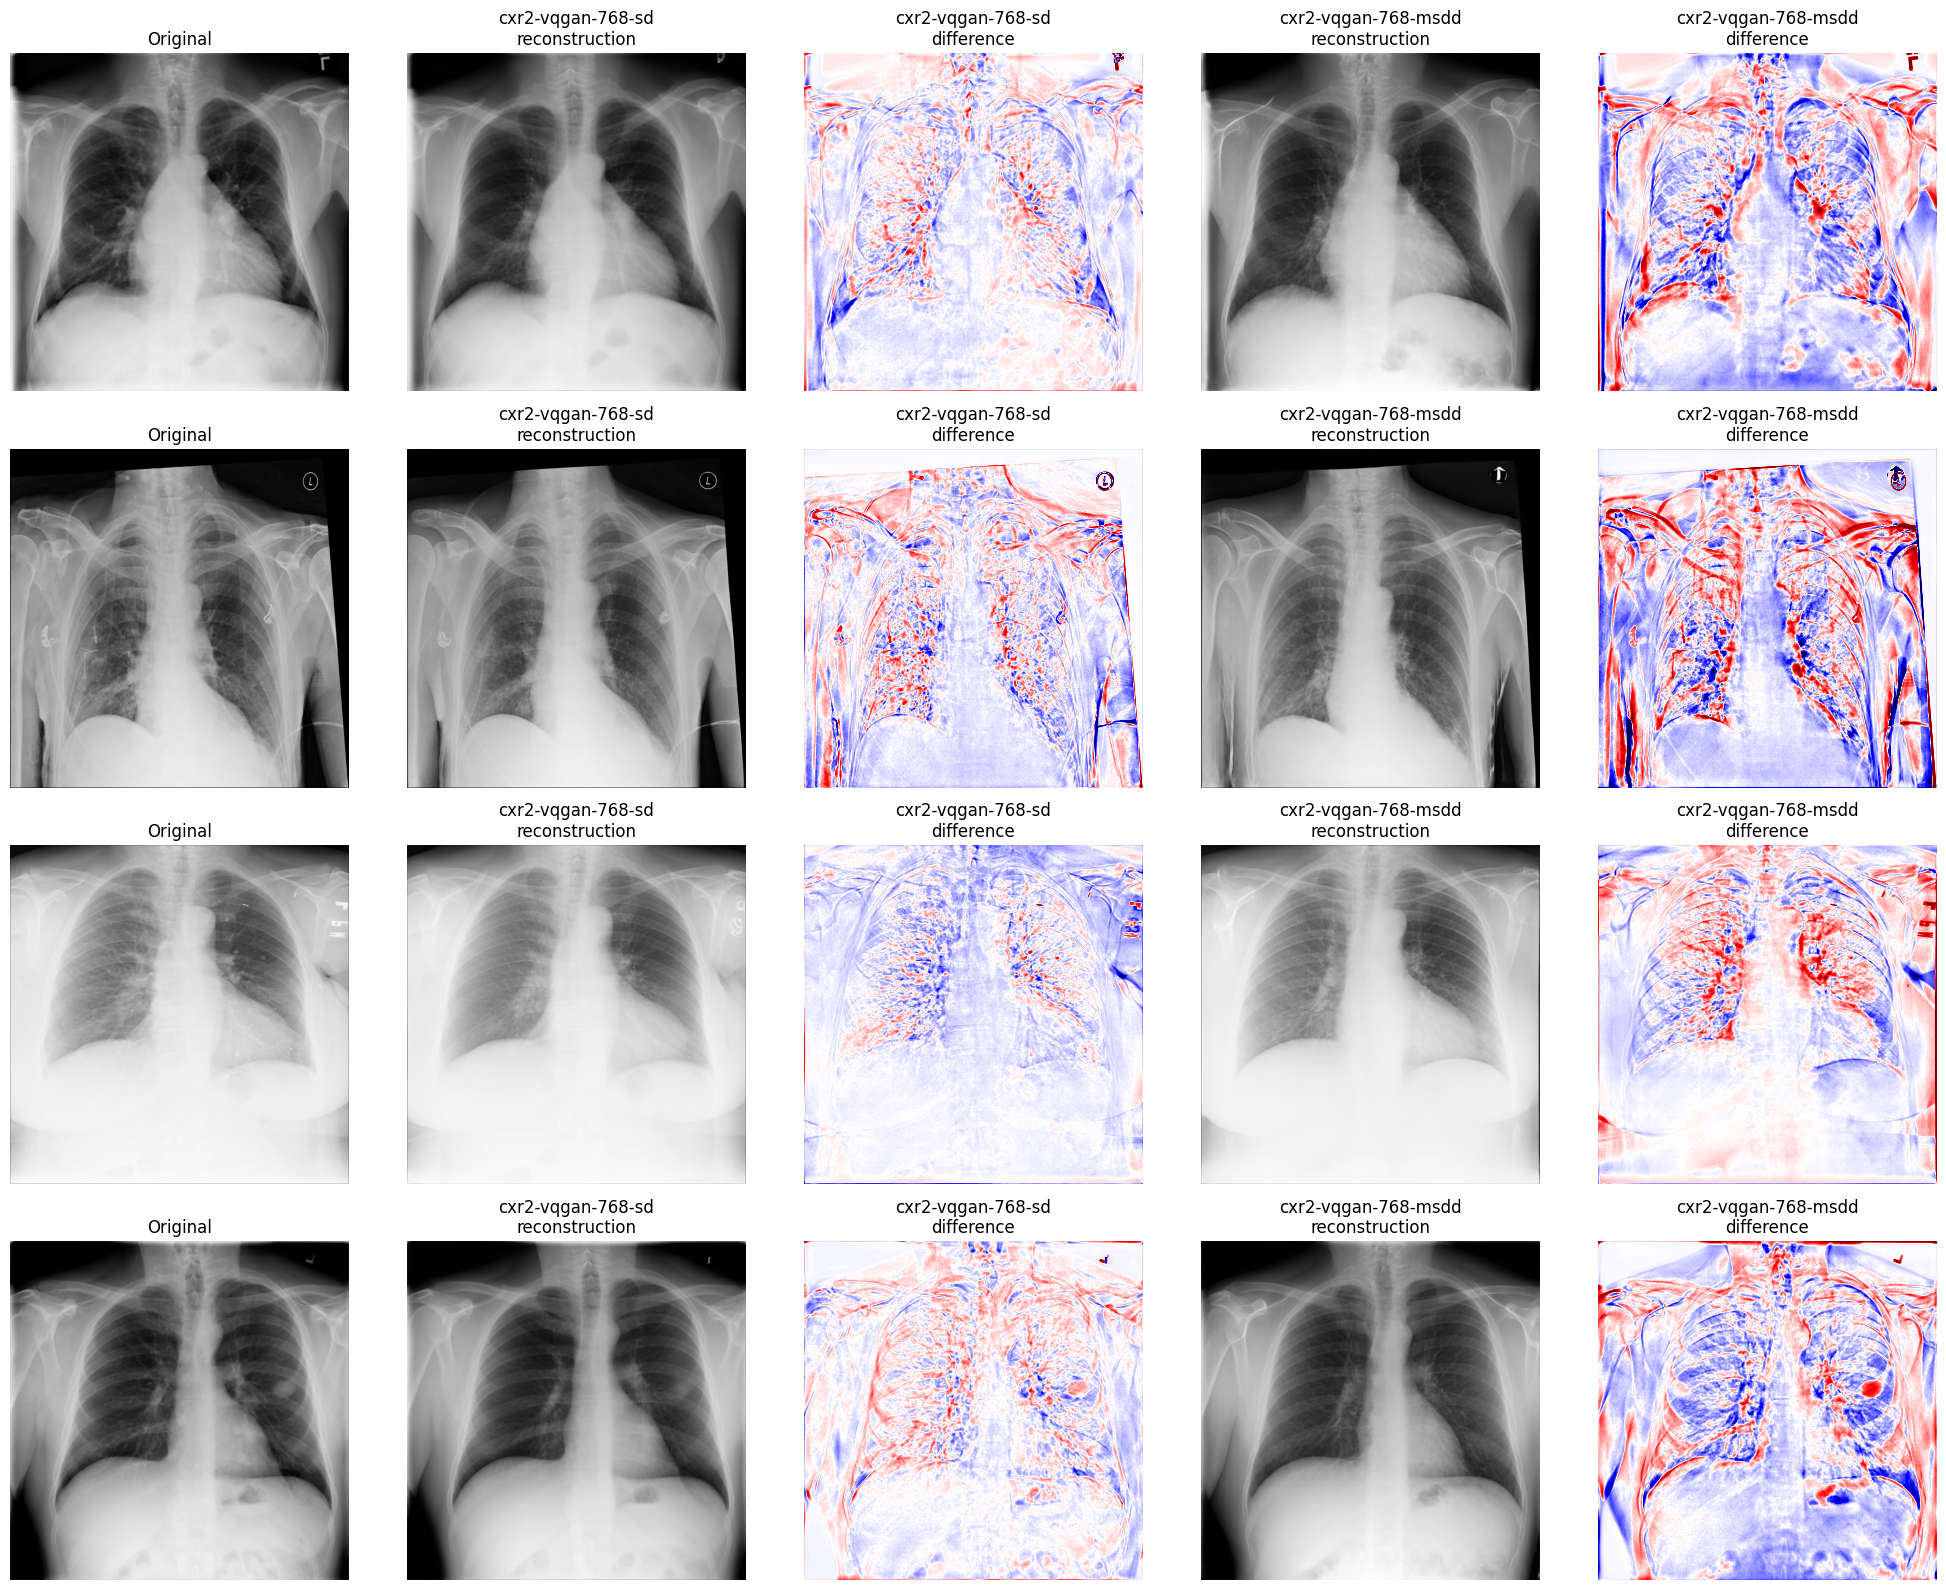

In [5]:
fig, axs = plt.subplots(len(files), 5, figsize=(20, 4 * len(files)))
for r, row in enumerate(axs):
    row[0].imshow(imgs[r, 0], cmap="gray", vmin=-1024, vmax=1024); row[0].set_title("Original")
    for c, w in enumerate(vqs):
        row[1 + 2 * c].imshow(recons[w][r, 0], cmap="gray", vmin=-1024, vmax=1024)
        row[1 + 2 * c].set_title(f"{w}\nreconstruction")
        row[2 + 2 * c].imshow(diffs[w][r, 0], cmap="seismic", vmin=-512, vmax=512)
        row[2 + 2 * c].set_title(f"{w}\ndifference")
    for ax in row:
        ax.axis("off")
plt.tight_layout()

## The latent space

The latent `z` is a grid of codebook vectors (channels x height x width). Each position is one of the codebook entries, so an image is stored as a small map of discrete codes. The larger model uses a coarser grid with a bigger codebook. Shown here for the first image.

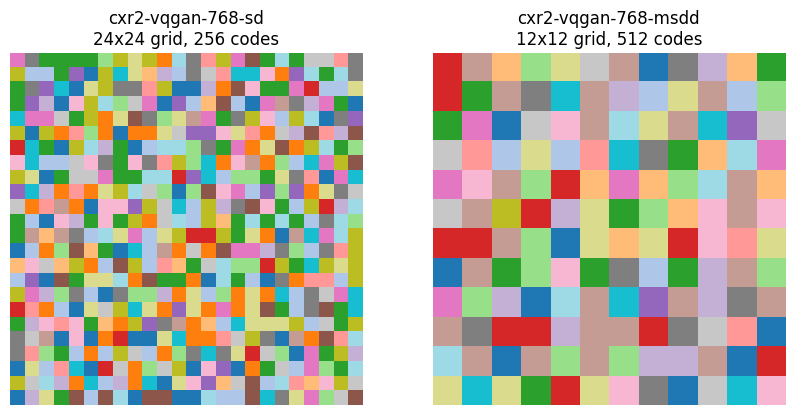

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
for ax, (w, vq) in zip(axs, vqs.items()):
    with torch.no_grad():
        # nearest codebook entry per latent position
        _, _, (_, _, indices) = vq.model.encode(vq.upsample(imgs[:1].repeat(1, 3, 1, 1) / 1024))
    ax.imshow(indices.reshape(zs[w].shape[2:]), cmap="tab20")
    ax.set_title(f"{w}\n{zs[w].shape[2]}x{zs[w].shape[3]} grid, {vq.model.quantize.n_e} codes")
    ax.axis("off")